# HW 1: Permutation tests

I used the sample dataset from Jupyter notebooks "iris.csv" which contains measurements from three different species of iris. I used a permutation test to compare if the setosa or the versicolor iris' came from the same distribution. 

Sample dataset found here: https://gist.github.com/netj/8836201

In [45]:
#import statements
import pandas as pd
import scipy
import numpy as np
from scipy.stats import permutation_test
from scipy import stats
import matplotlib.pyplot as plt


In [ ]:
# Read in "iris.csv"
df = pd.read_csv('iris.csv')
print(df)

In [ ]:
# get means of sample data 
def statistic(x, y, axis=0):
    return np.mean(x, axis=axis) - np.mean(y, axis=axis)

setosa = df[df['species'] == 'setosa']
versicolor = df[df['species'] == 'versicolor']
virginica = df[df['species'] == 'virginica']

#print to test
setosa


,sepal_length,sepal_width,petal_length,petal_width,species
0,4.9,3.0,1.4,0.2,setosa
1,4.7,3.2,1.3,0.2,setosa
2,4.6,3.1,1.5,0.2,setosa
3,5.0,3.6,1.4,0.2,setosa
4,5.4,3.9,1.7,0.4,setosa
5,4.6,3.4,1.4,0.3,setosa
6,5.0,3.4,1.5,0.2,setosa
7,4.4,2.9,1.4,0.2,setosa
8,4.9,3.1,1.5,0.1,setosa
9,5.4,3.7,1.5,0.2,setosa


In [10]:
# permutation test of sepal length 
res = permutation_test(
    (setosa['sepal_length'], versicolor['sepal_length']), 
    statistic, 
    permutation_type = 'independent',
    vectorized=True, 
    n_resamples=9999, 
    alternative='two-sided'
)

print(f"Observed Statistic: {res.statistic:.4f}")
print(f"P-value: {res.pvalue:.4f}")

Observed Statistic: -0.9319
P-value: 0.0002


Null Distribution Array:
[ 0.14293878  0.02979592  0.30861224 ... -0.07930612  0.12677551
 -0.11163265]


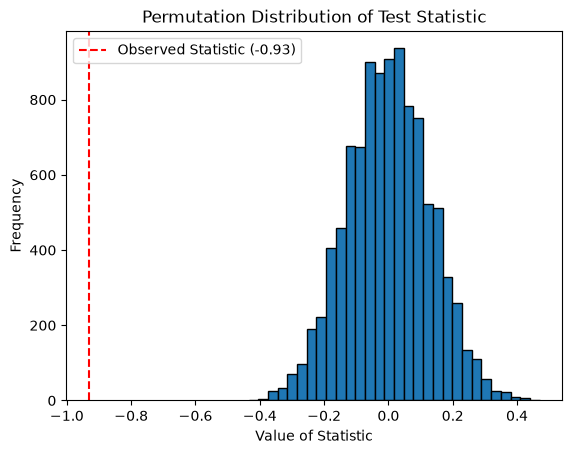

In [ ]:
# plot data to see null vs calculated distribution
print("Null Distribution Array:")
print(res.null_distribution)

plt.hist(res.null_distribution, bins=30, edgecolor='black')
plt.axvline(res.statistic, color='red', linestyle='--', label=f'Observed Statistic ({res.statistic:.2f})')
plt.title("Permutation Distribution of Test Statistic")
plt.xlabel("Value of Statistic")
plt.ylabel("Frequency")
plt.legend()
plt.show()


![Image showing what an iris sepal length refers to](iris_pic.png)


Example photos of the different species of iris in this dataset

### Using a two-sided permutation test, we can determine that the sepal lengths of the *iris setosa* is significantly different from that of the *iris versicolor* with a p-value<0.05 

# Using multiple variables

Since this dataset contains mutliple measurements, I can also run a permutation test with mutliple variables to compare the two iris populations. Importantly, I must compare to multiple comparisons before making a statistical claim. Now, in addition to sepal length, I also test for sepal_width, petal_length, and petal_width. 

In [12]:
def multi_variable_permutation_test(group_A, group_B, n_permutations=10000, seed=42):
    """
    Performs an independent two-sample permutation test on multiple variables.
    group_A, group_B: Arrays of shape (n_samples, n_variables)
    """
    rng = np.random.default_rng(seed)

    n_A = group_A.shape[0]
    n_B = group_B.shape[0]
    n_variables = setosa.shape[1]
    
    observed_diff = np.mean(group_A, axis=0) - np.mean(group_B, axis=0)
    
    combined = np.vstack([group_A, group_B])
    n_total = n_A + n_B
    
    extreme_count = np.zeros(n_variables)
    
    # Actual permutation
    for _ in range(n_permutations):
        shuffled_indices = rng.permutation(n_total)
        shuffled_combined = combined[shuffled_indices]
        
        perm_A = shuffled_combined[:n_A]
        perm_B = shuffled_combined[n_A:]
        
        perm_diff = np.mean(perm_A, axis=0) - np.mean(perm_B, axis=0)
        
        # Two sided test
        extreme_count += np.abs(perm_diff) >= np.abs(observed_diff)
        
    # uncorrect p vals
    p_values = extreme_count / n_permutations
    
    return observed_diff, p_values



In [35]:
setosa = setosa.iloc[:, :-1]
versicolor = versicolor.iloc[:,:-1]

In [ ]:
g_A = setosa
g_B = versicolor

# correct for multiple comparisons 
diffs, p_vals = multi_variable_permutation_test(g_A, g_B, n_permutations=5000)
adjusted_p_values = stats.false_discovery_control(p_vals, method='bh')
diffs, p_vals, adjusted_p_values

(sepal_length   -0.910204
 sepal_width     0.655102
 petal_length   -2.785714
 petal_width    -1.079592
 dtype: float64,
 sepal_length    0.0
 sepal_width     0.0
 petal_length    0.0
 petal_width     0.0
 dtype: float64,
 array([0., 0., 0., 0.]))